[λ=0] Epoch 1, Loss=696.28, Sparsity=0.00%
[λ=0] Epoch 2, Loss=588.73, Sparsity=0.00%
[λ=0] Epoch 3, Loss=532.25, Sparsity=0.00%
[λ=0] Epoch 4, Loss=489.44, Sparsity=0.00%
[λ=0] Epoch 5, Loss=452.23, Sparsity=0.00%
[λ=0] Epoch 6, Loss=414.69, Sparsity=0.00%
[λ=0] Epoch 7, Loss=380.17, Sparsity=0.00%
[λ=0] Epoch 8, Loss=341.86, Sparsity=0.00%
[λ=0] Epoch 9, Loss=305.10, Sparsity=0.00%
[λ=0] Epoch 10, Loss=270.09, Sparsity=0.00%
[λ=0] Epoch 11, Loss=234.05, Sparsity=0.00%
[λ=0] Epoch 12, Loss=199.65, Sparsity=0.00%
[λ=0] Epoch 13, Loss=171.46, Sparsity=0.00%
[λ=0] Epoch 14, Loss=147.07, Sparsity=0.00%
[λ=0] Epoch 15, Loss=126.13, Sparsity=0.00%
[λ=0] Epoch 16, Loss=110.74, Sparsity=0.00%
[λ=0] Epoch 17, Loss=93.57, Sparsity=0.00%
[λ=0] Epoch 18, Loss=85.05, Sparsity=0.00%
[λ=0] Epoch 19, Loss=77.23, Sparsity=0.00%
[λ=0] Epoch 20, Loss=72.47, Sparsity=0.00%
[λ=0] Epoch 21, Loss=64.21, Sparsity=0.00%
[λ=0] Epoch 22, Loss=55.85, Sparsity=0.00%
[λ=0] Epoch 23, Loss=62.97, Sparsity=0.00%
[λ=0

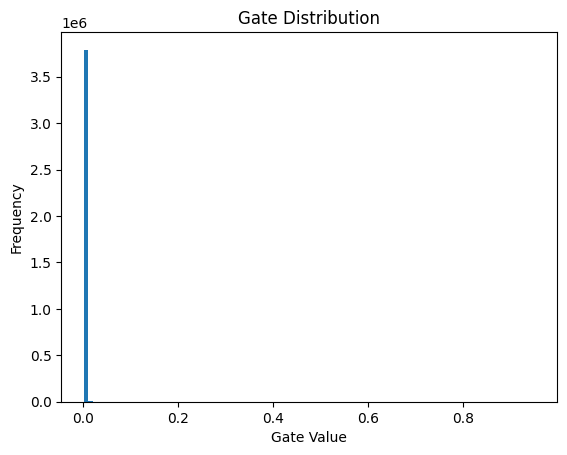

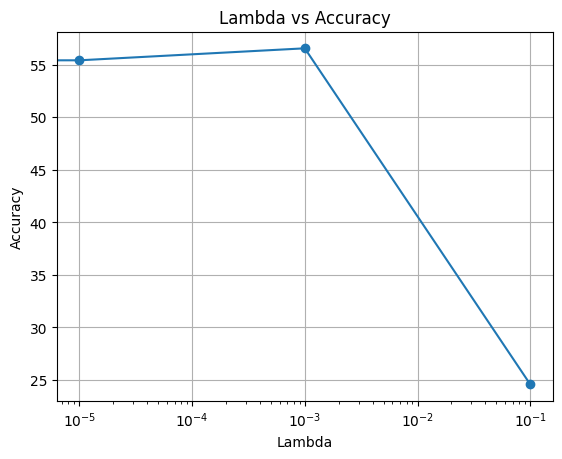

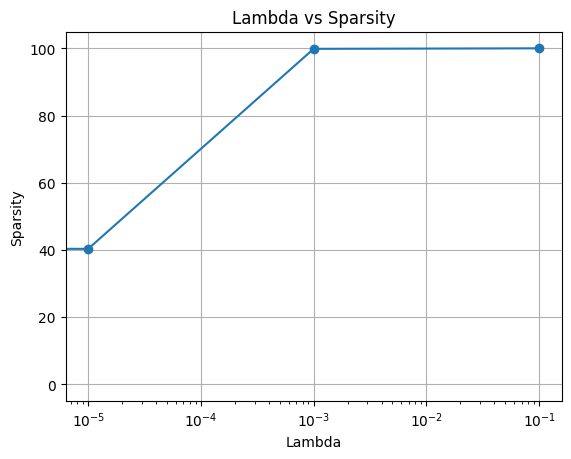

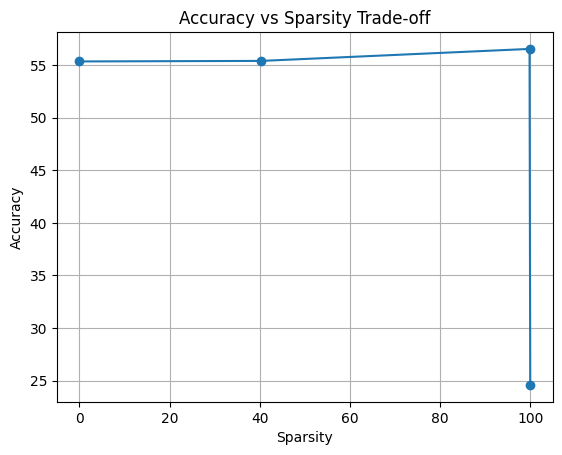

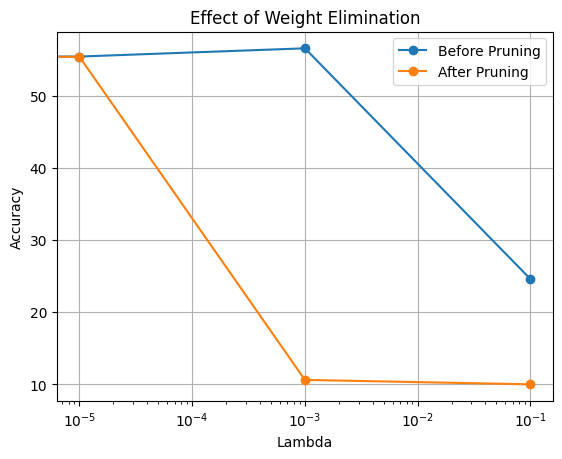

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = "mps" if torch.mps.is_available() else "cpu"

# ----------------------------
# Prunable Linear Layer
# ----------------------------
class PrunableLinear(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()

        self.weight = nn.Parameter(torch.randn(out_features, in_features) * 0.01)
        self.bias = nn.Parameter(torch.zeros(out_features))

        # Better init (stable)
        self.gate_scores = nn.Parameter(torch.zeros(out_features, in_features))

    def forward(self, x):
        gates = torch.sigmoid(self.gate_scores)
        pruned_weights = self.weight * gates
        return F.linear(x, pruned_weights, self.bias)

    def get_gate_values(self):
        return torch.sigmoid(self.gate_scores)


# ----------------------------
# Model (MLP)
# ----------------------------
class PrunableMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = PrunableLinear(32*32*3, 1024)
        self.fc2 = PrunableLinear(1024, 512)
        self.fc3 = PrunableLinear(512, 256)
        self.fc4 = PrunableLinear(256, 10)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        return self.fc4(x)

    #  SUM (as per paper)
    def sparsity_loss(self):
        loss = 0
        for m in self.modules():
            if isinstance(m, PrunableLinear):
                loss += m.get_gate_values().sum()
        return loss

    def compute_sparsity(self, threshold=0.02):
        total, pruned = 0, 0
        for m in self.modules():
            if isinstance(m, PrunableLinear):
                gates = m.get_gate_values()
                total += gates.numel()
                pruned += (gates < threshold).sum().item()
        return 100 * pruned / total


# ----------------------------
# Utility Functions
# ----------------------------
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            outputs = model(x)
            _, pred = torch.max(outputs, 1)
            total += y.size(0)
            correct += (pred == y).sum().item()

    return 100 * correct / total


def prune_model(model, threshold=0.02):
    for m in model.modules():
        if isinstance(m, PrunableLinear):
            gates = torch.sigmoid(m.gate_scores)
            mask = (gates > threshold).float()
            m.weight.data *= mask


def plot_gate_distribution(model):
    gates = []
    for m in model.modules():
        if isinstance(m, PrunableLinear):
            gates.extend(m.get_gate_values().detach().cpu().numpy().flatten())

    plt.figure()
    plt.hist(gates, bins=100)
    plt.title("Gate Distribution")
    plt.xlabel("Gate Value")
    plt.ylabel("Frequency")
    plt.savefig("gate_distribution.png")
    plt.show()


def plot_lambda_results(results):
    lambdas = [r[0] for r in results]
    accuracies = [r[1] for r in results]
    sparsities = [r[2] for r in results]

    plt.figure()
    plt.plot(lambdas, accuracies, marker='o')
    plt.xscale('log')
    plt.xlabel("Lambda")
    plt.ylabel("Accuracy")
    plt.title("Lambda vs Accuracy")
    plt.grid()
    plt.show()

    plt.figure()
    plt.plot(lambdas, sparsities, marker='o')
    plt.xscale('log')
    plt.xlabel("Lambda")
    plt.ylabel("Sparsity")
    plt.title("Lambda vs Sparsity")
    plt.grid()
    plt.show()

    plt.figure()
    plt.plot(sparsities, accuracies, marker='o')
    plt.xlabel("Sparsity")
    plt.ylabel("Accuracy")
    plt.title("Accuracy vs Sparsity Trade-off")
    plt.grid()
    plt.show()


def plot_pruning_effect(pruned_results):
    lambdas = [r[0] for r in pruned_results]
    before = [r[1] for r in pruned_results]
    after = [r[2] for r in pruned_results]

    plt.figure()
    plt.plot(lambdas, before, marker='o', label='Before Pruning')
    plt.plot(lambdas, after, marker='o', label='After Pruning')
    plt.xscale('log')
    plt.xlabel("Lambda")
    plt.ylabel("Accuracy")
    plt.title("Effect of Weight Elimination")
    plt.legend()
    plt.grid()
    plt.show()


# ----------------------------
# Data
# ----------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = torchvision.datasets.CIFAR10("./data", train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=128, shuffle=True)

testset = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=128, shuffle=False)


# ----------------------------
# Training Function
# ----------------------------
def train_model(lambda_sparse):
    model = PrunableMLP().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(30):
        model.train()
        total_loss = 0

        for x, y in trainloader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            outputs = model(x)
            ce_loss = criterion(outputs, y)
            sparsity_loss = model.sparsity_loss()

            # Warm-up (critical)
            if epoch < 5:
                loss = ce_loss
            else:
                loss = ce_loss + lambda_sparse * sparsity_loss

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"[λ={lambda_sparse}] Epoch {epoch+1}, Loss={total_loss:.2f}, Sparsity={model.compute_sparsity():.2f}%")

    acc = evaluate(model, testloader)
    sparsity = model.compute_sparsity()

    return model, acc, sparsity


# ----------------------------
# Experiments
# ----------------------------
lambda_values = [0, 1e-5,1e-4, 5e-4]

models = []
results = []
pruned_results = []

for lam in lambda_values:
    model, acc, sparsity = train_model(lam)

    results.append((lam, acc, sparsity))
    models.append(model)

    # Before pruning
    before_acc = acc

    # Apply pruning
    prune_model(model)

    # After pruning
    after_acc = evaluate(model, testloader)

    pruned_results.append((lam, before_acc, after_acc))


# ----------------------------
# Final Outputs
# ----------------------------
print("\nFinal Results:")
for r in results:
    print(f"Lambda: {r[0]}, Accuracy: {r[1]:.2f}%, Sparsity: {r[2]:.2f}%")

# Best model
best_idx = max(range(len(results)), key=lambda i: results[i][1])
best_model = models[best_idx]

# Visualizations
plot_gate_distribution(best_model)
plot_lambda_results(results)
plot_pruning_effect(pruned_results)

In [4]:
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            outputs = model(x)
            _, pred = torch.max(outputs, 1)

            total += y.size(0)
            correct += (pred == y).sum().item()

    return 100 * correct / total

In [5]:
test_results = []

for i, model in enumerate(models):
    acc = evaluate(model, testloader)

    test_results.append((lambda_values[i], acc))

    print(f"Lambda: {lambda_values[i]}, Test Accuracy: {acc:.2f}%")

Lambda: 0, Test Accuracy: 55.35%
Lambda: 1e-05, Test Accuracy: 55.37%
Lambda: 0.001, Test Accuracy: 10.61%
Lambda: 0.1, Test Accuracy: 10.00%


In [6]:
# 🔹 baseline from TEST accuracy
baseline_acc = test_results[0][1]  # λ = 0

best_idx = None
best_sparsity = -1

for i, (lam, test_acc) in enumerate(test_results):
    sparsity = results[i][2]  # get sparsity from training results

    # Allow small drop (2%) from TEST baseline
    if test_acc >= baseline_acc - 2:
        if sparsity > best_sparsity:
            best_sparsity = sparsity
            best_idx = i

# fallback (if none satisfies condition)
if best_idx is None:
    best_idx = max(range(len(test_results)), key=lambda i: test_results[i][1])

best_model = models[best_idx]

print(f"\nSelected Lambda: {results[best_idx][0]}")
print(f"Test Accuracy: {test_results[best_idx][1]:.2f}%")
print(f"Sparsity: {results[best_idx][2]:.2f}%")


Selected Lambda: 1e-05
Test Accuracy: 55.37%
Sparsity: 40.33%


In [11]:
def plot_gate_distribution(model):
    gates = []
    for m in model.modules():
        if isinstance(m, PrunableLinear):
            gates.extend(m.get_gate_values().detach().cpu().numpy().flatten())

    plt.figure()
    plt.hist(gates, bins=100)
    plt.title("Gate Distribution")
    plt.xlabel("Gate Value")
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.savefig("gate_distribution.png", dpi=300)  #  high-quality save
    plt.show()
    plt.close()

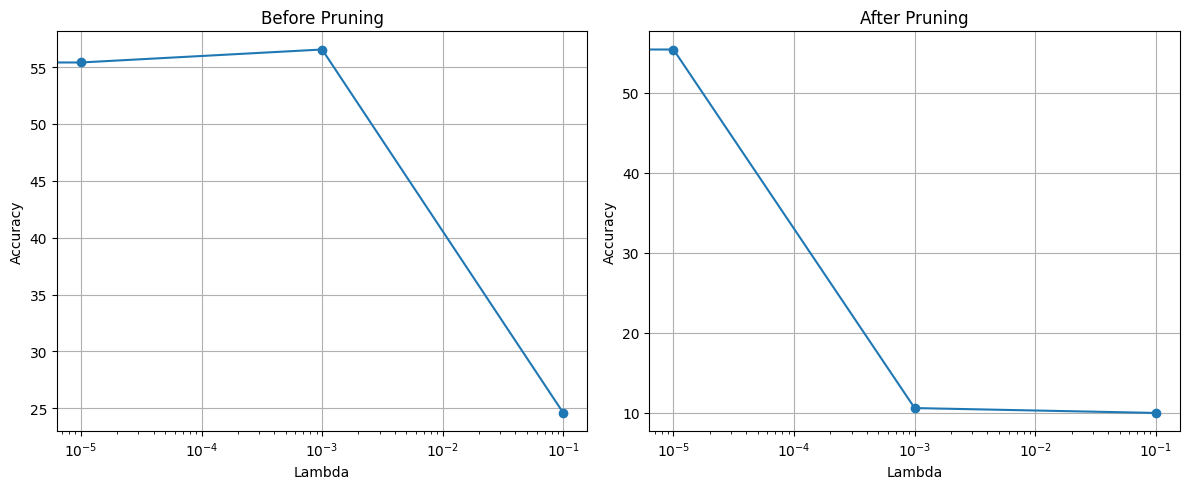

In [15]:
def plot_pruning_effect(pruned_results):
    lambdas = [r[0] for r in pruned_results]
    before = [r[1] for r in pruned_results]
    after = [r[2] for r in pruned_results]

    # 🔥 Create horizontal layout
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # 🔹 Left: Before Pruning
    axes[0].plot(lambdas, before, marker='o')
    axes[0].set_xscale('log')
    axes[0].set_title("Before Pruning")
    axes[0].set_xlabel("Lambda")
    axes[0].set_ylabel("Accuracy")
    axes[0].grid()

    # 🔹 Right: After Pruning
    axes[1].plot(lambdas, after, marker='o')
    axes[1].set_xscale('log')
    axes[1].set_title("After Pruning")
    axes[1].set_xlabel("Lambda")
    axes[1].set_ylabel("Accuracy")
    axes[1].grid()

    
    plt.tight_layout()

   
    plt.savefig("pruning_effect_horizontal.png", dpi=300)

    plt.show()
    plt.close()
plot_pruning_effect(pruned_results)

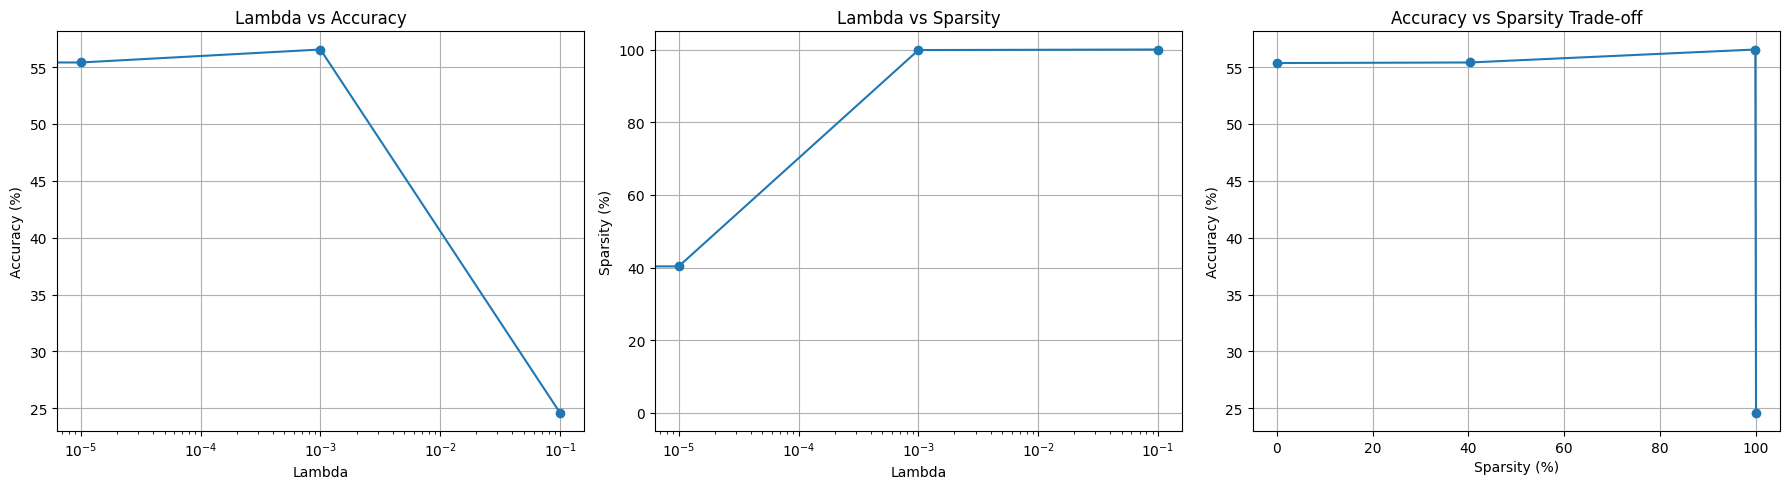

In [17]:
def plot_lambda_results(results):
    lambdas = [r[0] for r in results]
    accuracies = [r[1] for r in results]
    sparsities = [r[2] for r in results]

    # 🔥 Create horizontal layout (1 row, 3 plots)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 🔹 Plot 1: Lambda vs Accuracy
    axes[0].plot(lambdas, accuracies, marker='o')
    axes[0].set_xscale('log')
    axes[0].set_xlabel("Lambda")
    axes[0].set_ylabel("Accuracy (%)")
    axes[0].set_title("Lambda vs Accuracy")
    axes[0].grid()

    # 🔹 Plot 2: Lambda vs Sparsity
    axes[1].plot(lambdas, sparsities, marker='o')
    axes[1].set_xscale('log')
    axes[1].set_xlabel("Lambda")
    axes[1].set_ylabel("Sparsity (%)")
    axes[1].set_title("Lambda vs Sparsity")
    axes[1].grid()

    # 🔹 Plot 3: Accuracy vs Sparsity
    axes[2].plot(sparsities, accuracies, marker='o')
    axes[2].set_xlabel("Sparsity (%)")
    axes[2].set_ylabel("Accuracy (%)")
    axes[2].set_title("Accuracy vs Sparsity Trade-off")
    axes[2].grid()

  
    plt.tight_layout()

 
    plt.savefig("lambda_analysis_horizontal.png", dpi=300)

    plt.show()
    plt.close()

plot_lambda_results(results)